# Tutorial 09 — GCNs on NYC taxi zones

The nodes are named taxi zones and the signal is hourly pickup demand. Historical lags form each node's feature vector; a graph convolution lets related zones exchange information. We keep the neural network simple and focus on the modelling decision that matters most here: **what does an edge mean?**

We compare geographical proximity, POI similarity, socioeconomic similarity and training-period mobility connectivity. The design is inspired by ST-MGCN, but this notebook uses a small residual GCN rather than reproducing the paper's full architecture.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `09 Graph neural networks`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [ ]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "09 Graph neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics. PyTorch builds the neural networks used in this lesson.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [ ]:
%pip install numpy pandas matplotlib scikit-learn torch


In [1]:
import json,warnings,numpy as np,pandas as pd,matplotlib.pyplot as plt,torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_absolute_error,mean_squared_error
warnings.filterwarnings("ignore"); torch.manual_seed(42); np.random.seed(42)
flow=pd.read_csv("nyc_zone_hour.csv.gz",parse_dates=["time"]); zones=pd.read_csv("nyc_zone_features.csv").sort_values("LocationID"); conn=pd.read_csv("nyc_training_connectivity.csv.gz"); geo=json.load(open("nyc_taxi_zones.geojson"))
ids=zones.LocationID.astype(int).tolist(); names=zones.Zone.tolist(); N=len(ids); pos={z:i for i,z in enumerate(ids)}
pivot=flow.pivot(index="time",columns="zone_id",values="pickups").reindex(columns=ids); print("demand matrix:",pivot.shape,"nodes:",N); display(zones[["LocationID","Borough","Zone","population_density","poi_total"]].head())

demand matrix: (1440, 67) nodes: 67


,LocationID,Borough,Zone,population_density,poi_total
0,4,Manhattan,Alphabet City,22583.252308,82.0
1,12,Manhattan,Battery Park,182789.383885,119.0
2,13,Manhattan,Battery Park City,40456.011567,119.0
3,24,Manhattan,Bloomingdale,43105.467858,51.0
4,41,Manhattan,Central Harlem,36338.268541,150.0


In [2]:
def polygons(feature):
    g=feature["geometry"]
    return g["coordinates"] if g["type"]=="MultiPolygon" else [g["coordinates"]]

def zone_map(values, title, cmap="viridis", ax=None, colorbar=True):
    values=pd.Series(values)
    if ax is None: _,ax=plt.subplots(figsize=(8,7))
    norm=plt.Normalize(values.min(), values.max() if values.max()>values.min() else values.min()+1)
    for f in geo["features"]:
        zid=int(f["properties"]["LocationID"]); value=values.get(zid,np.nan)
        color="lightgrey" if pd.isna(value) else plt.colormaps[cmap](norm(value))
        for poly in polygons(f):
            ax.fill(*np.asarray(poly[0]).T,facecolor=color,edgecolor="white",linewidth=.45)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    if colorbar: plt.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=ax,shrink=.7)
    return ax

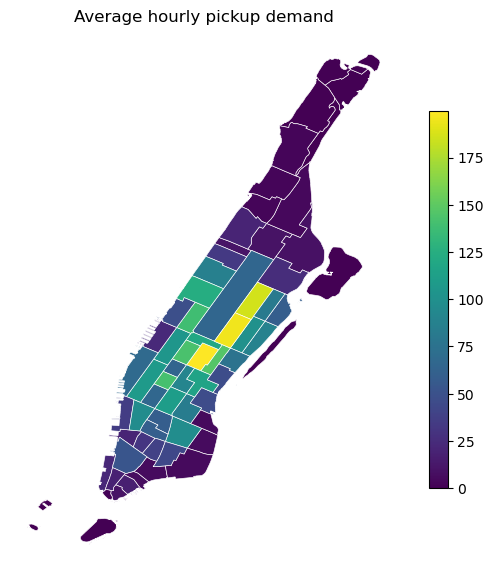

In [3]:
zone_map(pivot.mean(),"Average hourly pickup demand"); plt.show()

## Four definitions of an edge

Let $d_{ij}$ be centroid distance, $\mathbf{p}_i$ the POI vector, $\mathbf{s}_i$ the standardized population/employment vector, and $F_{ij}^{\mathrm{train}}$ the number of training-period trips. We construct four similarity matrices:

$$S_{ij}^{\mathrm{geo}}=\exp[-(d_{ij}/\sigma_d)^2],$$

$$S_{ij}^{\mathrm{poi}}=\cos[\log(1+\mathbf{p}_i),\log(1+\mathbf{p}_j)],$$

$$S_{ij}^{\mathrm{soc}}=\exp[-\lVert\mathbf{s}_i-\mathbf{s}_j\rVert_2^2/2],$$

$$S_{ij}^{\mathrm{mob}}=\log[1+F_{ij}^{\mathrm{train}}+F_{ji}^{\mathrm{train}}].$$

For each node we retain the strongest $k$ links, symmetrise them with $W_{ij}=\max(S_{ij},S_{ji})$, and remove the diagonal. The message matrix is row-normalised:

$$P=D^{-1}W,\qquad D_{ii}=\sum_j W_{ij}.$$

The self contribution is kept in a separate neural-network branch. This prevents repeated neighbour averaging from erasing a zone's own recent demand.

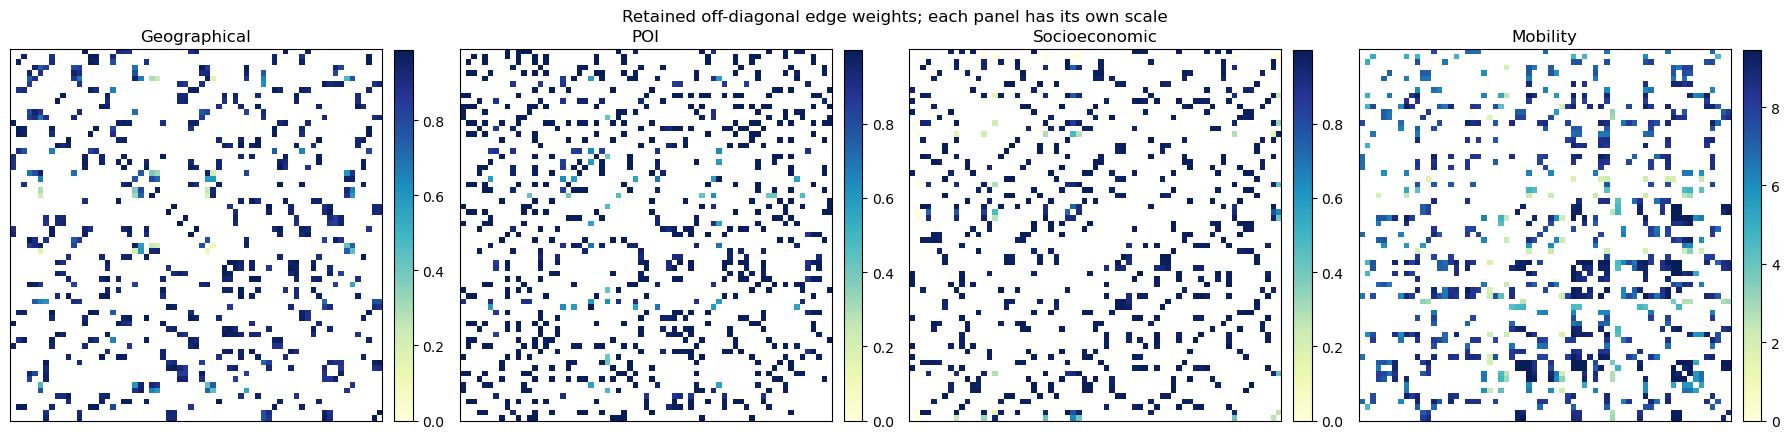

In [4]:
lat=zones.latitude.to_numpy()
lon=zones.longitude.to_numpy()

def haversine_matrix(lat,lon):
    a1=np.radians(lat[:,None])
    a2=np.radians(lat[None,:])
    delta_lon=np.radians(lon[:,None]-lon[None,:])
    x=np.sin((a1-a2)/2)**2+np.cos(a1)*np.cos(a2)*np.sin(delta_lon/2)**2
    return 6371*2*np.arcsin(np.sqrt(x))

dist=haversine_matrix(lat,lon)
poi_columns=["food_facilities","health_facilities","retail_facilities","education_facilities","transport_facilities"]
poi=zones[poi_columns].to_numpy()
socio=StandardScaler().fit_transform(zones[["population_density","employment_density"]])
distance_scale=np.median(dist[dist>0])
base={
    "Geographical":np.exp(-(dist/distance_scale)**2),
    "POI":cosine_similarity(np.log1p(poi)),
    "Socioeconomic":np.exp(-((socio[:,None,:]-socio[None,:,:])**2).sum(2)/2),
}

mobility=np.zeros((N,N))
for row in conn.itertuples():
    if row.origin in pos and row.destination in pos:
        i=pos[row.origin]
        j=pos[row.destination]
        mobility[i,j]+=row.flow
        mobility[j,i]+=row.flow
base["Mobility"]=np.log1p(mobility)

def retain_top_k(W,k):
    W=W.copy()
    np.fill_diagonal(W,0)
    retained=np.zeros_like(W)
    for i in range(N):
        neighbours=np.argpartition(W[i],-k)[-k:]
        retained[i,neighbours]=W[i,neighbours]
    retained=np.maximum(retained,retained.T)
    np.fill_diagonal(retained,0)
    return retained

def neighbour_matrix(W,k):
    retained=retain_top_k(W,k)
    row_sum=retained.sum(axis=1,keepdims=True)
    return np.divide(retained,row_sum,out=np.zeros_like(retained),where=row_sum>0)

graphs={name:neighbour_matrix(W,8) for name,W in base.items()}
fig,axes=plt.subplots(1,4,figsize=(18,4.4))
for ax,(name,W) in zip(axes,base.items()):
    edge_weights=retain_top_k(W,8)
    positive=edge_weights[edge_weights>0]
    vmax=np.quantile(positive,0.95)
    shown=np.ma.masked_where(edge_weights==0,edge_weights)
    image=ax.imshow(shown,cmap="YlGnBu",vmin=0,vmax=vmax)
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(image,ax=ax,fraction=0.046,pad=0.03)
plt.suptitle("Retained off-diagonal edge weights; each panel has its own scale")
plt.tight_layout()

In [5]:
focus=names.index("Midtown Center") if "Midtown Center" in names else 0
neighbour_table={}
for graph_name,P in graphs.items():
    ranked=np.argsort(P[focus])[::-1]
    ranked=ranked[P[focus,ranked]>0][:5]
    neighbour_table[graph_name]=[names[j] for j in ranked]
display(pd.DataFrame(neighbour_table,index=["1","2","3","4","5"]).rename_axis("neighbour rank"))

,Geographical,POI,Socioeconomic,Mobility
neighbour rank,,,,
1,Midtown East,Midtown South,West Chelsea/Hudson Yards,Upper East Side South
2,Times Sq/Theatre District,Seaport,Meatpacking/West Village West,Upper East Side North
3,Midtown North,UN/Turtle Bay South,Randalls Island,Penn Station/Madison Sq West
4,Garment District,Midtown East,Garment District,Midtown North
5,Sutton Place/Turtle Bay North,Sutton Place/Turtle Bay North,Roosevelt Island,Midtown South


## Identical temporal features for baselines and GCNs

For target hour $t$, every model receives the same eight features for zone $i$:

$$\mathbf{x}_{i,t}=[y_{i,t-1},y_{i,t-2},y_{i,t-3},y_{i,t-24},y_{i,t-168},\sin(h_t),\cos(h_t),\mathrm{weekend}_t].$$

Linear regression, Lasso, Ridge and ANN predict from $\mathbf{x}_{i,t}$ alone. A GCN receives the same vector and additionally aggregates $\sum_jP_{ij}\mathbf{x}_{j,t}$ from related zones. Therefore any difference comes from spatial information rather than a different history window.

Each sample has shape `[nodes, features]`, and its target contains next-hour demand for all nodes. Demand lags and targets are standardised with training-period statistics only.

In [ ]:
Y=pivot.to_numpy(float)
times=pivot.index
lags=[1,2,3,24,168]
feature_names=["lag_1","lag_2","lag_3","lag_24","lag_168","hour_sin","hour_cos","weekend"]
samples=[]
targets=[]
target_times=[]
for t in range(max(lags),len(Y)):
 cal=[np.sin(2*np.pi*times[t].hour/24),np.cos(2*np.pi*times[t].hour/24),int(times[t].dayofweek>=5)]
 samples.append(np.column_stack([Y[t-l] for l in lags]+[np.full(N,x) for x in cal]))
 targets.append(Y[t])
 target_times.append(times[t])
X_raw=np.asarray(samples)
T=np.asarray(targets)
target_times=pd.DatetimeIndex(target_times)
tr=target_times<"2024-02-10"
va=(target_times>="2024-02-10")&(target_times<"2024-02-20")
te=target_times>="2024-02-20"
mean=T[tr].mean(axis=0)
std=T[tr].std(axis=0).clip(1)

# Keep explicit raw splits for inspection and reporting.
X_train=X_raw[tr]
y_train=T[tr]
X_valid=X_raw[va]
y_valid=T[va]
X_test=X_raw[te]
y_test=T[te]

# A separate copy is standardized only for fitting the neural/regularized models.
X=X_raw.copy()
X[:,:,:5]=(X[:,:,:5]-mean[None,:,None])/std[None,:,None]
Z=(T-mean)/std
print("Raw supervised-learning arrays:")
print("X_train:",X_train.shape,"y_train:",y_train.shape)
print("X_valid:",X_valid.shape,"y_valid:",y_valid.shape)
print("X_test :",X_test.shape,"y_test :",y_test.shape)
print("X = samples × taxi-zone nodes × 8 node features.")
print("y = samples × taxi-zone nodes; values are next-hour pickups.")
print("Feature order:",feature_names)
example_zone=names.index("Midtown Center") if "Midtown Center" in names else 0
print("Example raw feature row for",names[example_zone],"(lag values are pickups/hour):")
display(pd.DataFrame([X_train[0,example_zone]],columns=feature_names))
print("Scaling is used only inside model fitting; validation/test MAE and plots use pickups per hour.")

In [ ]:
class NodeMLP(nn.Module):
    def __init__(self,n_features,hidden):
        super().__init__()
        self.hidden=nn.Linear(n_features,hidden)
        self.output=nn.Linear(hidden,1)

    def forward(self,x):
        # x is a tabular node-row matrix: (samples × zones, features).
        correction=self.output(torch.relu(self.hidden(x))).squeeze(-1)
        return x[:,0]+correction

class ResidualGCN(nn.Module):
    def __init__(self,P,n_features,hidden):
        super().__init__()
        self.register_buffer("P",torch.tensor(P,dtype=torch.float32))
        self.self_layer=nn.Linear(n_features,hidden)
        self.neighbour_layer=nn.Linear(n_features,hidden,bias=False)
        self.neighbour_gate=nn.Parameter(torch.tensor(-2.0))
        self.output=nn.Linear(hidden,1)

    def forward(self,x):
        neighbour_features=torch.einsum("ij,bjf->bif",self.P,x)
        gate=torch.sigmoid(self.neighbour_gate)
        hidden=self.self_layer(x)+gate*self.neighbour_layer(neighbour_features)
        correction=self.output(torch.relu(hidden)).squeeze(-1)
        return x[:,:,0]+correction

def neural_arrays(model,mask):
    if isinstance(model,NodeMLP):
        x_model=X[mask].reshape(-1,X.shape[-1])
        y_model=Z[mask].reshape(-1)
        unit_scale=np.tile(std,mask.sum())
    else:
        x_model=X[mask]
        y_model=Z[mask]
        unit_scale=std
    return x_model,y_model,unit_scale


def fit_neural(model,max_epochs=500,lr=0.003,patience=40,min_delta=5e-4):
    optimizer=torch.optim.Adam(model.parameters(),lr=lr,weight_decay=1e-4)
    loss_fn=nn.MSELoss()
    x_train_array,y_train_array,train_scale=neural_arrays(model,tr)
    x_valid_array,y_valid_array,valid_scale=neural_arrays(model,va)
    x_train=torch.tensor(x_train_array,dtype=torch.float32)
    y_train=torch.tensor(y_train_array,dtype=torch.float32)
    x_valid=torch.tensor(x_valid_array,dtype=torch.float32)
    y_valid=torch.tensor(y_valid_array,dtype=torch.float32)
    best_loss=float("inf")
    best_state=None
    best_epoch=0
    waiting=0
    history={"train MAE":[],"validation MAE":[]}
    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        train_loss=loss_fn(model(x_train),y_train)
        train_loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            train_prediction=model(x_train)
            valid_prediction=model(x_valid)
            valid_loss=loss_fn(valid_prediction,y_valid).item()
            train_scale_tensor=torch.tensor(train_scale,dtype=torch.float32)
            valid_scale_tensor=torch.tensor(valid_scale,dtype=torch.float32)
            train_mae=torch.abs(
                (train_prediction-y_train)*train_scale_tensor
            ).mean().item()
            valid_mae=torch.abs(
                (valid_prediction-y_valid)*valid_scale_tensor
            ).mean().item()
        history["train MAE"].append(train_mae)
        history["validation MAE"].append(valid_mae)
        if valid_loss<best_loss-min_delta:
            best_loss=valid_loss
            best_state={key:value.detach().clone() for key,value in model.state_dict().items()}
            best_epoch=epoch+1
            waiting=0
        else:
            waiting+=1
        if waiting>=patience:
            break
    model.load_state_dict(best_state)
    return model,history,best_epoch

def train_fixed_epochs(model,mask,epochs,lr=0.003):
    optimizer=torch.optim.Adam(model.parameters(),lr=lr,weight_decay=1e-4)
    loss_fn=nn.MSELoss()
    x_fit_array,y_fit_array,_=neural_arrays(model,mask)
    x_fit=torch.tensor(x_fit_array,dtype=torch.float32)
    y_fit=torch.tensor(y_fit_array,dtype=torch.float32)
    for _ in range(max(1,int(epochs))):
        model.train()
        optimizer.zero_grad()
        loss=loss_fn(model(x_fit),y_fit)
        loss.backward()
        optimizer.step()
    return model

def predict_neural(model,mask):
    x_model,_,_=neural_arrays(model,mask)
    model.eval()
    with torch.no_grad():
        standardized=model(torch.tensor(x_model,dtype=torch.float32)).numpy()
    standardized=np.asarray(standardized).reshape(mask.sum(),N)
    return np.clip(standardized*std+mean,0,None)

## Fair baselines and validation search

Linear regression, Lasso, Ridge and ANN use a two-dimensional node-row matrix $(N_{samples}N_{zones},F)$: every row describes one zone at one target hour. The residual GCN instead receives a node-feature tensor $(N_{samples},N_{zones},F)$ plus an adjacency matrix $(N_{zones},N_{zones})$, so it can aggregate neighbouring zones. It has the same local branch as ANN and adds one gated neighbour branch:

$$\mathbf{h}_{i,t}=\mathrm{ReLU}[W_s\mathbf{x}_{i,t}+gW_n\sum_jP_{ij}\mathbf{x}_{j,t}],\qquad 0<g<1.$$

Internally, the output predicts a correction to a training-standardized persistence value $x_{i,t}^{(t-1)}$; every reported prediction and error is converted back to pickups per hour. This residual structure lets a GCN retain the strong local history and use neighbours only when validation supports them. An identity adjacency contains no spatial information and is therefore reported more clearly as the node-wise ANN baseline.

We tune Lasso/Ridge regularisation, ANN width, and the number of neighbours $k$ using validation data. Neural models use early stopping with up to 500 epochs, so a poor graph result cannot be attributed simply to an arbitrary 70-epoch cutoff.

In [ ]:
def flatten_node_rows(mask):
    return X[mask].reshape(-1,X.shape[-1]),Z[mask].reshape(-1)

def restore_demand(standardized,n_samples):
    standardized=np.asarray(standardized).reshape(n_samples,N)
    return np.clip(standardized*std+mean,0,None)

X_train_flat,y_train_flat=flatten_node_rows(tr)
X_valid_flat,y_valid_flat=flatten_node_rows(va)
print("Linear/Lasso/Ridge/ANN input:",X_train_flat.shape,"= (samples × zones, features)")
print("GCN node-feature input:",X[tr].shape,"= (samples, zones, features)")
print("Each GCN also receives adjacency:",next(iter(base.values())).shape,"= (zones, zones)")
validation_rows=[]

linear_grids={
    "Linear regression":[None],
    "Lasso":[0.0001,0.001,0.01],
    "Ridge":[0.1,1.0,10.0],
}
for family,settings in linear_grids.items():
    for setting in settings:
        if family=="Linear regression":
            model=LinearRegression()
        elif family=="Lasso":
            model=Lasso(alpha=setting,max_iter=5000)
        else:
            model=Ridge(alpha=setting)
        model.fit(X_train_flat,y_train_flat)
        pred=restore_demand(model.predict(X_valid_flat),va.sum())
        validation_rows.append({
            "family":family,"setting":setting,"hidden":np.nan,"k":np.nan,
            "validation_MAE":mean_absolute_error(T[va].ravel(),pred.ravel()),
            "best_epoch":np.nan,"neighbour_gate":np.nan,
        })

neural_cache={}
for hidden in [16,32,64]:
    torch.manual_seed(42)
    model=NodeMLP(X.shape[-1],hidden)
    model,history,best_epoch=fit_neural(model)
    pred=predict_neural(model,va)
    key=("ANN",0,hidden)
    neural_cache[key]=(model,history,best_epoch)
    validation_rows.append({
        "family":"ANN","setting":"width","hidden":hidden,"k":0,
        "validation_MAE":mean_absolute_error(T[va].ravel(),pred.ravel()),
        "best_epoch":best_epoch,"neighbour_gate":0.0,
    })

validation=pd.DataFrame(validation_rows)
best_ann=validation[validation.family.eq("ANN")].sort_values("validation_MAE").iloc[0]
shared_hidden=int(best_ann.hidden)

graph_rows=[]
for graph_name,W in base.items():
    for k in [2,4,8]:
        P=neighbour_matrix(W,k)
        torch.manual_seed(42)
        model=ResidualGCN(P,X.shape[-1],shared_hidden)
        model,history,best_epoch=fit_neural(model)
        pred=predict_neural(model,va)
        gate=float(torch.sigmoid(model.neighbour_gate).detach())
        key=(graph_name,k,shared_hidden)
        neural_cache[key]=(model,history,best_epoch)
        graph_rows.append({
            "family":graph_name,"setting":"neighbours","hidden":shared_hidden,"k":k,
            "validation_MAE":mean_absolute_error(T[va].ravel(),pred.ravel()),
            "best_epoch":best_epoch,"neighbour_gate":gate,
        })
validation=pd.concat([validation,pd.DataFrame(graph_rows)],ignore_index=True)
selected=validation.loc[validation.groupby("family").validation_MAE.idxmin()].sort_values("validation_MAE")
display(validation.sort_values(["family","validation_MAE"]).round(4))
print("Validation-selected setting for every model family:")
display(selected.round(4))

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for family in ["Geographical","POI","Socioeconomic","Mobility"]:
    subset=validation[validation.family.eq(family)].sort_values("k")
    axes[0].plot(subset.k,subset.validation_MAE,marker="o",linewidth=2,label=family)
axes[0].set(title="Validation sensitivity to number of neighbours",xlabel="k neighbours",ylabel="MAE")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.2)

best_graph=selected[selected.family.isin(base)].iloc[0]
best_key=(best_graph.family,int(best_graph.k),int(best_graph.hidden))
best_history=neural_cache[best_key][1]
axes[1].plot(best_history["train MAE"],label="train",linewidth=2)
axes[1].plot(best_history["validation MAE"],label="validation",linewidth=2)
axes[1].axvline(int(best_graph.best_epoch)-1,color="#D62728",linestyle="--",label="selected epoch")
axes[1].set(title=f"Training convergence: {best_graph.family} GCN",xlabel="epoch",ylabel="MAE [pickups per zone-hour]")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.2)
plt.tight_layout()

## Freeze every family before the test comparison

The validation curves show whether training converged and identify the early-stopping epoch. After selecting one setting per family, we refit it on train + validation for that many epochs and evaluate the test period once.

The older two-layer graph model repeatedly averaged node signals before prediction. Because recent demand at the same zone is very strong, that design could oversmooth the useful local lags and perform worse than the identity graph. The residual GCN above keeps the complete node-wise ANN path and adds neighbour information through a learned gate.

,model,MAE,RMSE
2,Mobility GCN,9.685,18.804
1,Geographical GCN,9.749,18.930
3,POI GCN,9.767,19.050
4,Socioeconomic GCN,9.826,19.199
5,ANN,9.958,19.704
6,Linear regression,11.078,21.890
7,Ridge,11.078,21.890
8,Lasso,11.080,21.893
0,Persistence,15.018,29.204


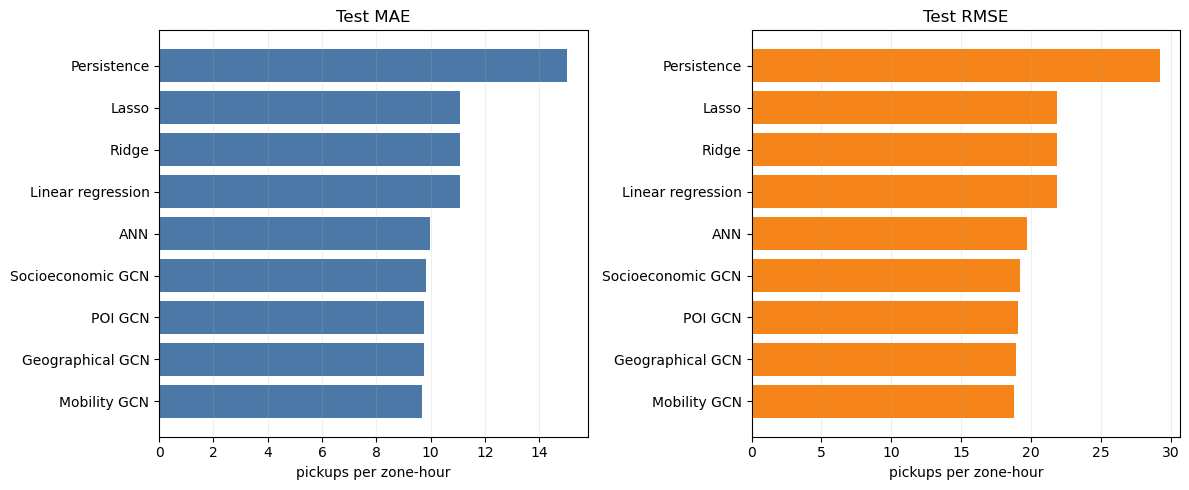

In [9]:
fit_mask=tr|va
X_fit_flat,y_fit_flat=flatten_node_rows(fit_mask)
X_test_flat,_=flatten_node_rows(te)
predictions={"Persistence":np.clip(X[te,:,0]*std+mean,0,None)}

for _,choice in selected.iterrows():
    family=choice.family
    if family=="Linear regression":
        model=LinearRegression()
        model.fit(X_fit_flat,y_fit_flat)
        predictions[family]=restore_demand(model.predict(X_test_flat),te.sum())
    elif family=="Lasso":
        model=Lasso(alpha=float(choice.setting),max_iter=5000)
        model.fit(X_fit_flat,y_fit_flat)
        predictions[family]=restore_demand(model.predict(X_test_flat),te.sum())
    elif family=="Ridge":
        model=Ridge(alpha=float(choice.setting))
        model.fit(X_fit_flat,y_fit_flat)
        predictions[family]=restore_demand(model.predict(X_test_flat),te.sum())
    elif family=="ANN":
        torch.manual_seed(42)
        model=NodeMLP(X.shape[-1],int(choice.hidden))
        model=train_fixed_epochs(model,fit_mask,int(choice.best_epoch))
        predictions[family]=predict_neural(model,te)
    else:
        P=neighbour_matrix(base[family],int(choice.k))
        torch.manual_seed(42)
        model=ResidualGCN(P,X.shape[-1],int(choice.hidden))
        model=train_fixed_epochs(model,fit_mask,int(choice.best_epoch))
        predictions[f"{family} GCN"]=predict_neural(model,te)

rows=[]
for model_name,prediction in predictions.items():
    rows.append({
        "model":model_name,
        "MAE":mean_absolute_error(T[te].ravel(),prediction.ravel()),
        "RMSE":mean_squared_error(T[te].ravel(),prediction.ravel())**0.5,
    })
results=pd.DataFrame(rows).sort_values("MAE")
display(results.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,5))
ordered=results.sort_values("MAE",ascending=True)
axes[0].barh(ordered.model,ordered.MAE,color="#4C78A8")
axes[0].set(title="Test MAE",xlabel="pickups per zone-hour")
ordered=results.sort_values("RMSE",ascending=True)
axes[1].barh(ordered.model,ordered.RMSE,color="#F58518")
axes[1].set(title="Test RMSE",xlabel="pickups per zone-hour")
for ax in axes:
    ax.grid(axis="x",alpha=0.2)
plt.tight_layout()

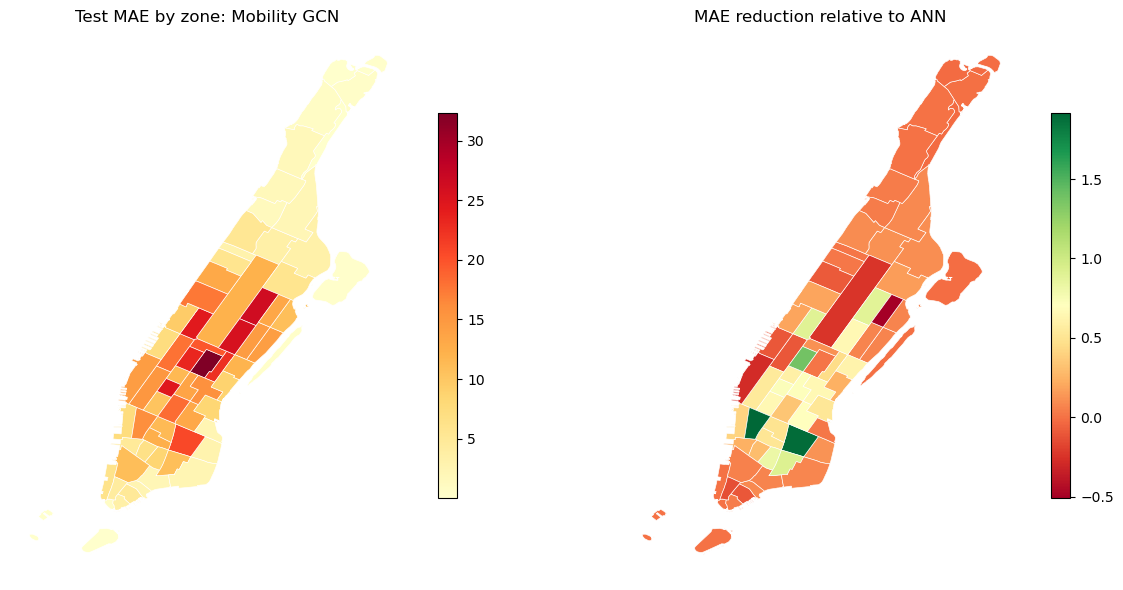

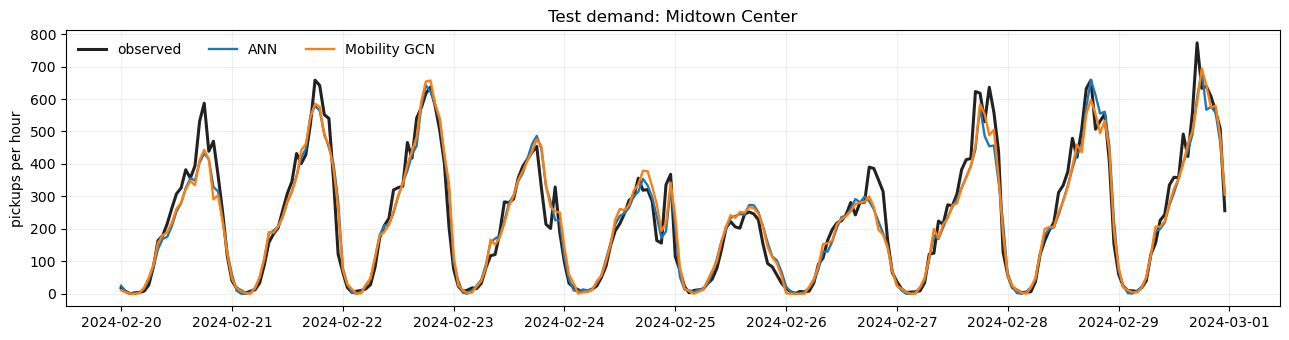

In [10]:
graph_names=[f"{name} GCN" for name in base]
best_gcn=results[results.model.isin(graph_names)].iloc[0].model
best_baseline=results[~results.model.isin(graph_names)].iloc[0].model
gcn_prediction=predictions[best_gcn]
baseline_prediction=predictions[best_baseline]
gcn_zone_mae=np.abs(T[te]-gcn_prediction).mean(axis=0)
baseline_zone_mae=np.abs(T[te]-baseline_prediction).mean(axis=0)
improvement=baseline_zone_mae-gcn_zone_mae
fig,axes=plt.subplots(1,2,figsize=(13,6))
zone_map(pd.Series(gcn_zone_mae,index=ids),f"Test MAE by zone: {best_gcn}",cmap="YlOrRd",ax=axes[0])
zone_map(pd.Series(improvement,index=ids),f"MAE reduction relative to {best_baseline}",cmap="RdYlGn",ax=axes[1])
plt.tight_layout()
plt.show()

for zone_name in ["Midtown Center","JFK Airport"]:
    if zone_name in names:
        j=names.index(zone_name)
        plt.figure(figsize=(13,3.5))
        plt.plot(target_times[te],T[te,j],label="observed",color="#222222",linewidth=2.2)
        plt.plot(target_times[te],baseline_prediction[:,j],label=best_baseline,linewidth=1.7)
        plt.plot(target_times[te],gcn_prediction[:,j],label=best_gcn,linewidth=1.7)
        plt.title(f"Test demand: {zone_name}")
        plt.ylabel("pickups per hour")
        plt.legend(frameon=False,ncol=3)
        plt.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()